# Dummy data: load and plot

Multislice (pyprismatic) simulations in `dinov3/dummy_data/`. Each `*_training.h5` file is one simulation:

| dataset | shape | meaning |
|---|---|---|
| `dataMeas` | (256, 256, T) | diffraction pattern at each thickness |
| `dataPots` | (256, 256, T) | potential-derived target at each thickness |
| `dataQz` | (256, 256, T) | signed map, same layout (likely the qz-resolved / HOLZ component) |
| `dataProbe` | (256, 256) | probe aperture in reciprocal space |
| `qx`, `qy` | 256 | reciprocal-space axes (1/Å) |
| `qz` | 250 | qz axis |
| `thicknesses` | T | sample thickness (Å) |

`simulation_dataframe.pkl` holds the metadata for each file, keyed by the file's UUID (material, probe semiangle, energy, …).

In [1]:
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

DATA_DIR = Path("/mnt/data/DINOV3/dinov3/dummy_data")
sorted(p.name for p in DATA_DIR.iterdir())

['a5f089b3-2a4f-4689-bf6a-3bb39515f525_training.h5',
 'c75e81af-44d4-4b36-a15a-da02f38d4d28_training.h5',
 'd4a6b046-8704-403a-8a45-f6ae81166873_training.h5',
 'predicted_bragg_spots.csv',
 'predicted_vs_gt_per_pattern.csv',
 'simulation_dataframe.pkl']

## Simulation metadata

In [2]:
meta = pd.read_pickle(DATA_DIR / "simulation_dataframe.pkl")   # pickle only references pandas/numpy/pathlib/uuid
meta.index = meta.index.astype(str)
cols = ["pretty_formula", "space_group_symbol", "probeSemiangle", "alphaBeamMax", "E0",
        "algorithm", "simulation_program", "cell_size", "sliceThickness", "simulation_seed"]
meta[cols]

,pretty_formula,space_group_symbol,probeSemiangle,alphaBeamMax,E0,algorithm,simulation_program,cell_size,sliceThickness,simulation_seed
d4a6b046-8704-403a-8a45-f6ae81166873,SiO2,P3_221,1,2,300,multislice,pyprismatic,"[50, 50, 500]",2,62546606
c75e81af-44d4-4b36-a15a-da02f38d4d28,SiO2,P3_221,2,4,300,multislice,pyprismatic,"[50, 50, 500]",2,50103156
a5f089b3-2a4f-4689-bf6a-3bb39515f525,SiO2,P3_221,4,8,300,multislice,pyprismatic,"[50, 50, 500]",2,28384840


## Load the HDF5 files

In [3]:
def load_sim(path):
    with h5py.File(path, "r") as h:
        d = {k: h[k][()] for k in h.keys()}
    d["qx"], d["qy"], d["qz"] = d["qx"].ravel(), d["qy"].ravel(), d["qz"].ravel()
    d["uuid"] = path.name.split("_")[0]
    return d

sims = [load_sim(p) for p in sorted(DATA_DIR.glob("*_training.h5"))]
for s in sims:
    s["meta"] = meta.loc[s["uuid"]] if s["uuid"] in meta.index else None
sims.sort(key=lambda s: s["meta"]["probeSemiangle"] if s["meta"] is not None else 0)

for s in sims:
    m = s["meta"]
    print(f"{s['uuid'][:8]}  {m['pretty_formula']}  probe α={m['probeSemiangle']} mrad  "
          f"E0={m['E0']} kV  thicknesses={s['thicknesses'].min()}–{s['thicknesses'].max()} Å ({len(s['thicknesses'])})")
    for k in ["dataMeas", "dataPots", "dataQz", "dataProbe"]:
        a = s[k]; print(f"    {k:9s} {a.shape}  min={a.min():.3g}  max={a.max():.3g}")

d4a6b046  SiO2  probe α=1 mrad  E0=300 kV  thicknesses=20–500 Å (25)
    dataMeas  (256, 256, 25)  min=4.37e-13  max=0.978
    dataPots  (256, 256, 25)  min=0.0217  max=4.33e+03
    dataQz    (256, 256, 25)  min=-0.0567  max=0.0567
    dataProbe (256, 256)  min=0  max=1
c75e81af  SiO2  probe α=2 mrad  E0=300 kV  thicknesses=20–500 Å (25)
    dataMeas  (256, 256, 25)  min=6.19e-12  max=0.996
    dataPots  (256, 256, 25)  min=0.0247  max=4.33e+03
    dataQz    (256, 256, 25)  min=-0.0472  max=0.0472
    dataProbe (256, 256)  min=0  max=1
a5f089b3  SiO2  probe α=4 mrad  E0=300 kV  thicknesses=20–500 Å (25)
    dataMeas  (256, 256, 25)  min=6.53e-12  max=1.39
    dataPots  (256, 256, 25)  min=0.0243  max=4.33e+03
    dataQz    (256, 256, 25)  min=-0.0494  max=0.0494
    dataProbe (256, 256)  min=0  max=1


In [4]:
def extent(s):
    qx, qy = s["qx"], s["qy"]
    return [qy[0], qy[-1], qx[-1], qx[0]]          # rows = qx, cols = qy

def label(s):
    m = s["meta"]
    return f"{m['pretty_formula']}, α={m['probeSemiangle']} mrad"

def show(ax, img, s, title, log=False, cmap="magma", **kw):
    if log:
        im = ax.imshow(img, extent=extent(s), cmap=cmap,
                       norm=LogNorm(vmin=max(img.max() * 1e-5, img[img > 0].min()), vmax=img.max()), **kw)
    else:
        im = ax.imshow(img, extent=extent(s), cmap=cmap, **kw)
    ax.set_title(title, fontsize=9); ax.set_xlabel("$q_y$ (1/Å)"); ax.set_ylabel("$q_x$ (1/Å)")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return im

## Overview: one thickness per file

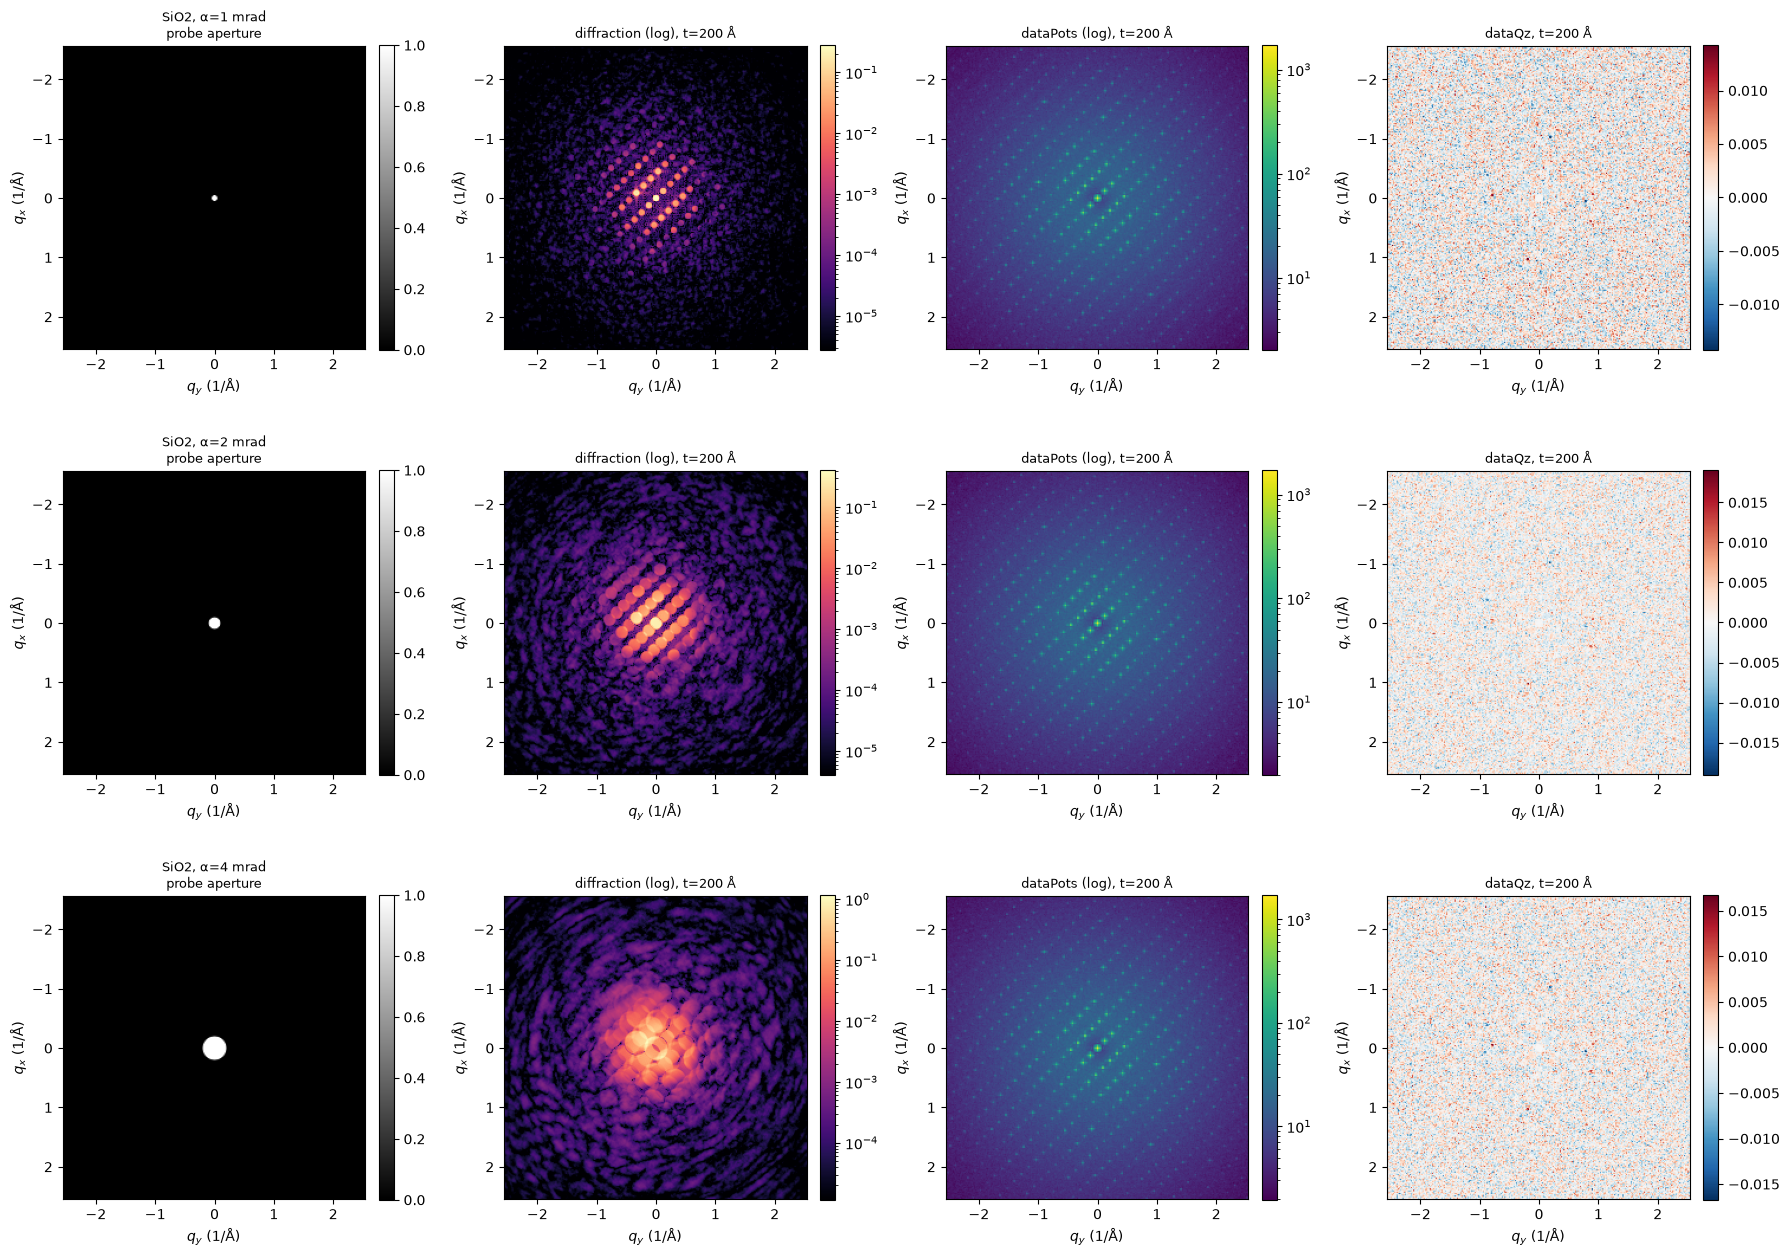

In [5]:
T_IDX = 9   # thickness index (0..24)

fig, axes = plt.subplots(len(sims), 4, figsize=(18, 4.3 * len(sims)))
for row, s in zip(np.atleast_2d(axes), sims):
    t = s["thicknesses"][T_IDX]
    show(row[0], s["dataProbe"], s, f"{label(s)}\nprobe aperture", cmap="gray")
    show(row[1], s["dataMeas"][..., T_IDX], s, f"diffraction (log), t={t} Å", log=True)
    show(row[2], s["dataPots"][..., T_IDX], s, f"dataPots (log), t={t} Å", log=True, cmap="viridis")
    v = np.abs(s["dataQz"][..., T_IDX]).max()
    show(row[3], s["dataQz"][..., T_IDX], s, f"dataQz, t={t} Å", cmap="RdBu_r", vmin=-v, vmax=v)
plt.tight_layout(); plt.show()

## Thickness series: diffraction patterns

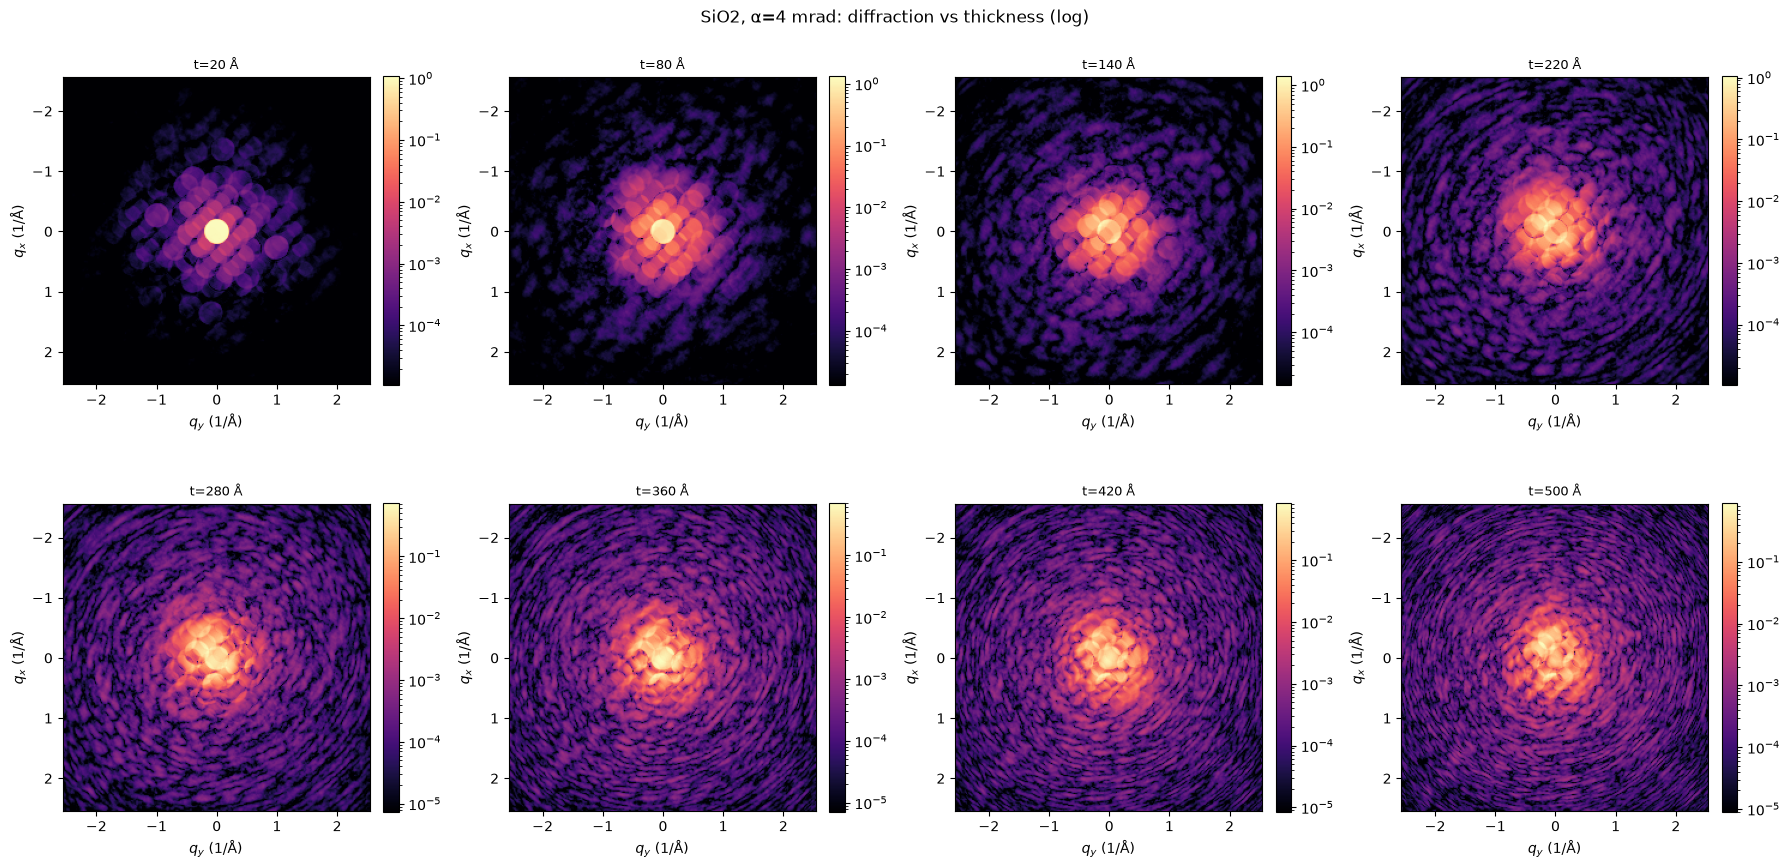

In [6]:
s = sims[-1]                      # change index to pick another probe semiangle
idx = np.linspace(0, len(s["thicknesses"]) - 1, 8).astype(int)

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, i in zip(axes.ravel(), idx):
    show(ax, s["dataMeas"][..., i], s, f"t={s['thicknesses'][i]} Å", log=True)
fig.suptitle(f"{label(s)}: diffraction vs thickness (log)"); plt.tight_layout(); plt.show()

## Same thickness, different probe semiangle (zoom on center)

In [ ]:
ZOOM = 1.0   # 1/Å half-width

fig, axes = plt.subplots(1, len(sims), figsize=(5.5 * len(sims), 5))
for ax, s in zip(np.atleast_1d(axes), sims):
    show(ax, s["dataMeas"][..., T_IDX], s, f"{label(s)}, t={s['thicknesses'][T_IDX]} Å", log=True)
    ax.set_xlim(-ZOOM, ZOOM); ax.set_ylim(-ZOOM, ZOOM)
plt.tight_layout(); plt.show()

## DINOv3 backbone: representations of diffraction + probe
Plain DINOv3 ViT-L/16 (SAT-493M), frozen, no DPT head / decoder. The central `CROP`×`CROP` detector px
(where the Bragg spots are) is upsampled to `SIZE`, so with CROP=128, SIZE=1024 each image gives a CLS embedding
(1024-d) and a 64×64 grid of patch embeddings, each patch covering 2×2 detector px.

In [ ]:
# ── Load plain DINOv3 ViT-L/16 backbone (no DPT head) ───────────────────────
# Backbone: DINOv3 ViT-L/16, SAT-493M pretraining (frozen, 24 blocks, 1024-d)
# Input: central CROP×CROP of the 256×256 detector image, upsampled to SIZE → (SIZE/16)² patch tokens
#        CROP=128, SIZE=1024 → 64×64 grid, 2 detector px per patch
import sys
import torch, torch.nn.functional as F

DINOV3_LOCATION  = "/mnt/data/DINOV3/dinov3"
BACKBONE_WEIGHTS = "/mnt/data/DINOV3/weights/dinov3_vitl16_pretrain_sat493m-eadcf0ff.pth"
IMG, SIZE = 256, 1024                # detector px, model input size
CROP      = 128                      # central crop in detector px (None = full image); 128 px ≈ ±1.28 1/Å
C0        = (IMG - CROP) // 2 if CROP else 0   # first detector px of the crop
DEVICE    = "cuda" if torch.cuda.is_available() else "cpu"
AUTOCAST_DTYPE = torch.float16       # T4: no native bf16

_MEAN = torch.tensor((0.485, 0.456, 0.406)).view(1, 3, 1, 1)
_STD  = torch.tensor((0.229, 0.224, 0.225)).view(1, 3, 1, 1)

def crop(img, c=CROP):
    """Central c×c crop of the last two axes (no-op if c is None)."""
    if not c:
        return img
    c0 = (img.shape[-1] - c) // 2
    return img[..., c0:c0 + c, c0:c0 + c]

def preprocess(imgs, mode="log", size=SIZE):
    """Central crop (CROP) → mode="log": log1p → per-image 1–99.9 % stretch (diffraction).
       mode="minmax": per-image min–max to [0, 1] (probe aperture, ~binary).
       Then → 3 channels → resize → ImageNet norm."""
    x = torch.as_tensor(crop(np.asarray(imgs)), dtype=torch.float32)
    if x.ndim == 2:
        x = x[None]
    flat = x.flatten(1)
    if mode == "log":
        x = torch.log1p(x.clamp_min(0)); flat = x.flatten(1)
        lo, hi = torch.quantile(flat, 0.01, dim=1), torch.quantile(flat, 0.999, dim=1)
    elif mode == "minmax":
        lo, hi = flat.min(1).values, flat.max(1).values
    else:
        raise ValueError(mode)
    x = ((x - lo[:, None, None]) / (hi - lo + 1e-6)[:, None, None]).clamp(0, 1)
    x = x[:, None].expand(-1, 3, -1, -1)
    if size != x.shape[-1]:
        x = F.interpolate(x, size=(size, size), mode="bilinear", align_corners=False)
    return (x - _MEAN) / _STD

sys.path.append(DINOV3_LOCATION)
backbone = torch.hub.load(DINOV3_LOCATION, "dinov3_vitl16", source="local", weights=BACKBONE_WEIGHTS)
backbone = backbone.to(DEVICE).eval().requires_grad_(False)

@torch.no_grad()
def encode(images, mode="log", bs=2):
    """images: list/array of 256×256 images (centre-cropped to CROP inside preprocess) →
         cls:     (N, 1024)          global embedding (normed CLS token)
         patches: (N, 1024, g, g)    patch-token embeddings, g = SIZE // 16"""
    cls, patches = [], []
    for i in range(0, len(images), bs):
        x = preprocess(images[i:i + bs], mode=mode).to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=AUTOCAST_DTYPE, enabled=DEVICE == "cuda"):
            out = backbone.forward_features(x)
        g = x.shape[-1] // backbone.patch_size
        p = out["x_norm_patchtokens"].float()
        cls.append(out["x_norm_clstoken"].float().cpu())
        patches.append(p.transpose(1, 2).reshape(len(x), -1, g, g).cpu())
    return torch.cat(cls).numpy(), torch.cat(patches).numpy()

def encode_sim(s, t_idx=None):
    """Representations for one simulation: its diffraction pattern(s) and its probe aperture."""
    meas = s["dataMeas"]
    diff = [meas[..., t_idx]] if t_idx is not None else [meas[..., i] for i in range(meas.shape[-1])]
    d_cls, d_patch = encode(diff, mode="log")
    p_cls, p_patch = encode([s["dataProbe"]], mode="minmax")
    return {"diff_cls": d_cls, "diff_patch": d_patch, "probe_cls": p_cls[0], "probe_patch": p_patch[0]}

n_par = sum(p.numel() for p in backbone.parameters())
print(f"DINOv3 ViT-L/16 (SAT-493M): embed_dim={backbone.embed_dim}  blocks={backbone.n_blocks}  "
      f"patch={backbone.patch_size}  |  {n_par/1e6:.0f} M params on {DEVICE}")

# quick check on one dummy-data pattern + its probe
rep = encode_sim(sims[0], t_idx=T_IDX)
for k, v in rep.items():
    print(f"  {k:12s} {v.shape}")

DINOv3 ViT-L/16 (SAT-493M): embed_dim=1024  blocks=24  patch=16  |  303 M params on cuda
  diff_cls     (1, 1024)
  diff_patch   (1, 1024, 64, 64)
  probe_cls    (1024,)
  probe_patch  (1024, 64, 64)


## Bragg-spot detection with a trained decoder
DINOv3 features are used as input to a small trained decoder that predicts Bragg-spot centres.
All patterns use the same centre crop (`CROP`=128 px → `SIZE`=1024, 64×64 tokens, 2 detector px per token)
and are scored against the same reference coordinates, for all three probe angles and the whole thickness series.

**Ground truth:** local maxima of `dataPots` in a 5×5 window and ≥ 5 % of the strongest reflection (keeps the 8.5 px
reciprocal lattice, drops side lobes), direct beam removed. A spot is **visible** when its disk in `dataMeas` is
≥ 3× brighter than the surrounding ring and ≥ 1/1000 of the brightest Bragg disk.

**Scoring:** score-ordered greedy matching within `MATCH_PX`: a detection on a GT spot = TP, on the direct beam
(or, in the *visible* protocol, on an invisible lattice point) = ignored, otherwise FP; unmatched GT spots = FN.
We report **recall at a fixed number of false positives per image** (1 and 5) and the median position error, under two
protocols: **visible** spots and **all** lattice reflections (the same labels for every angle; needed at 4 mrad, where
overlapping disks leave almost no spot visible). All distances are in detector pixels.

In [ ]:
# ── Settings, geometry, ground truth, matching ───────────────────────────────
from scipy.ndimage import maximum_filter
import pandas as pd

T_EVAL       = list(range(len(sims[0]["thicknesses"])))   # thickness indices to evaluate (all 25)
MATCH_PX     = 2.0        # detection ↔ GT matching radius
MIN_DIST_PX  = 4.0        # min distance between detected peaks (spot spacing here ≈ 8.5 px)
EDGE_PX      = 4          # GT / detections closer than this to the crop edge are not scored
GT_REL       = 0.05       # GT = dataPots maxima ≥ GT_REL × strongest non-direct reflection
GT_NMS       = 5          # local-max window (px) for dataPots; 5 + 5 % keeps the 8.5 px lattice, drops side lobes
VIS_RING     = (1, 3)     # visibility background ring: r+1 … r+3 px around the disk
VIS_CONTRAST = 3.0        # visible: disk ≥ 3 × ring ...
VIS_MIN_REL  = 1e-3       # ... and ≥ 1e-3 × brightest Bragg disk
FP_LEVELS    = (1, 5)     # recall is reported at these false positives per image

G_TOK = SIZE // backbone.patch_size              # tokens per side (64)
K_PX  = (CROP or IMG) / G_TOK                    # detector px per token (2.0)
LO, HI = C0 + EDGE_PX, C0 + (CROP or IMG) - 1 - EDGE_PX   # scored region (detector px, inclusive)

def patch_to_det(p):
    """Token index (fractional ok) → detector px.  Bilinear resize, align_corners=False: input px u sits at
    detector C0 + (u + 0.5)·CROP/SIZE − 0.5, and token j is centred on input px 16j + 7.5  →  C0 + K(j + ½) − ½."""
    return C0 + K_PX * (np.asarray(p, float) + 0.5) - 0.5

def det_to_patch(d):
    return (np.asarray(d, float) - C0 + 0.5) / K_PX - 0.5

assert np.isclose(patch_to_det(0), C0 + 0.5) and np.isclose(det_to_patch(patch_to_det(7.3)), 7.3)

def probe_geometry(probe):
    """Aperture centroid (row, col) in detector px and radius in px (from its area)."""
    w = (probe > 0.5).astype(float)
    yy, xx = np.mgrid[:probe.shape[0], :probe.shape[1]]
    return np.array([(w * yy).sum(), (w * xx).sum()]) / w.sum(), np.sqrt(w.sum() / np.pi)

def _offsets(r0, r1=None):
    R = int(np.ceil(r1 if r1 else r0)) + 1
    dy, dx = np.mgrid[-R:R + 1, -R:R + 1]; d = np.hypot(dy, dx)
    m = (d <= max(r0, 1.0)) if r1 is None else ((d > r0) & (d <= r1))
    return dy[m], dx[m]

def region_mean(img, centers, r0, r1=None):
    """Mean of img in a disk (radius r0) or ring (r0, r1] around each (row, col) centre."""
    dy, dx = _offsets(r0, r1)
    out = []
    for y, x in np.round(centers).astype(int):
        yy, xx = y + dy, x + dx
        ok = (yy >= 0) & (yy < img.shape[0]) & (xx >= 0) & (xx < img.shape[1])
        out.append(img[yy[ok], xx[ok]].mean())
    return np.asarray(out)

def in_region(pts, lo=LO, hi=HI):
    pts = np.asarray(pts).reshape(-1, 2)
    return np.all((pts >= lo - 0.5) & (pts <= hi + 0.5), axis=1)

def ground_truth(s, t, lo=LO, hi=HI):
    """→ dict(centers (n,2) sub-px, visible (n,), direct (2,)) for file s at thickness index t, inside [lo, hi]."""
    P, M = s["dataPots"][..., t], s["dataMeas"][..., t]
    c0, r = probe_geometry(s["dataProbe"])
    ij = np.argwhere(P == maximum_filter(P, size=GT_NMS))
    ij = ij[np.hypot(*(ij - c0).T) > 1.5]                                  # drop the direct beam
    v = P[tuple(ij.T)]; ij = ij[v >= GT_REL * v.max()]
    cen = []                                                               # sub-px: 3×3 centroid of dataPots
    for y, x in ij:
        y0, y1, x0, x1 = max(y - 1, 0), min(y + 2, P.shape[0]), max(x - 1, 0), min(x + 2, P.shape[1])
        w = P[y0:y1, x0:x1]; yy, xx = np.mgrid[y0:y1, x0:x1]
        cen.append([(w * yy).sum() / w.sum(), (w * xx).sum() / w.sum()])
    cen = np.asarray(cen).reshape(-1, 2)
    disk, ring = region_mean(M, cen, r), region_mean(M, cen, r + VIS_RING[0], r + VIS_RING[1])
    vis = (disk >= VIS_CONTRAST * ring) & (disk >= VIS_MIN_REL * disk.max())
    keep = in_region(cen, lo, hi)
    return dict(centers=cen[keep], visible=vis[keep], direct=c0)

def _greedy(det, targets, ignore, gate):
    used = np.zeros(len(targets), bool)
    status, err = np.zeros(len(det), int), np.full(len(det), np.nan)
    for i, d in enumerate(det):
        dv = np.hypot(*(targets - d).T) if len(targets) else np.array([])
        cand = np.where((dv <= gate) & ~used)[0]
        if len(cand):
            j = cand[np.argmin(dv[cand])]; used[j] = True; status[i], err[i] = 1, dv[j]
        elif len(ignore) and np.hypot(*(ignore - d).T).min() <= gate:
            status[i] = -1
    return status, err

def match(det, gt, gate=MATCH_PX):
    """det sorted by score (desc). Two protocols, status per detection 1 TP / 0 FP / −1 ignored, error px (NaN if not TP):
       "vis": targets = visible spots, invisible lattice points + direct beam ignored;
       "all": targets = every lattice reflection (same labels for every angle), direct beam ignored."""
    c, v, direct = gt["centers"], gt["visible"], gt["direct"][None]
    return dict(zip(("status", "err"), _greedy(det, c[v], np.vstack([c[~v], direct]), gate)),
                **dict(zip(("status_all", "err_all"), _greedy(det, c, direct, gate))))

def froc(rows, proto="vis"):
    """Pool per-image results → (fp per image, recall, score thresholds), score-descending.
    proto "vis": recall of visible spots; "all": recall of all lattice reflections."""
    sk, nk = ("status", "n_vis") if proto == "vis" else ("status_all", "n_all")
    sc = np.concatenate([r["scores"] for r in rows]); st = np.concatenate([r[sk] for r in rows])
    keep = st >= 0; sc, st = sc[keep], st[keep]
    o = np.argsort(-sc); sc, st = sc[o], st[o]
    n_gt, n_img = sum(r[nk] for r in rows), len(rows)
    return np.cumsum(st == 0) / n_img, np.cumsum(st == 1) / max(n_gt, 1), sc

def operating_point(rows, fp_per_img, proto="vis"):
    """Score threshold giving at most fp_per_img false positives per image (pooled over rows), and the recall there."""
    fppi, rec, sc = froc(rows, proto)
    ok = np.where(fppi <= fp_per_img)[0]
    return (sc[ok[-1]], rec[ok[-1]]) if len(ok) else (np.inf, 0.0)

g0 = ground_truth(sims[0], T_IDX)
print(f"token = {K_PX:.1f} px, scored region = detector px {LO}…{HI}")
print(f"example GT ({label(sims[0])}, t={sims[0]['thicknesses'][T_IDX]} Å): "
      f"{len(g0['centers'])} lattice maxima, {g0['visible'].sum()} visible, direct beam at {g0['direct']}")

In [ ]:
# ── Encode every diffraction pattern once with DINOv3 (decoder input) ────────
feat_cache = {}                                   # (file index, thickness index) → (1024, 64, 64) float16
for fi, s in enumerate(sims):
    _, dfeats = encode([s["dataMeas"][..., t] for t in T_EVAL], mode="log")
    for t, feat in zip(T_EVAL, dfeats):
        feat_cache[fi, t] = feat.astype(np.float16)
    print(f"{label(s)}: encoded {len(T_EVAL)} thicknesses")

## Trained spatial decoder (debug scale)
A small decoder predicts a **centre heatmap + sub-pixel offsets** at detector resolution (128×128 crop) from:

| Input | Role |
|---|---|
| frozen DINOv3 tokens (1024 × 64 × 64, encoded above) | context |
| raw diffraction crop (log-scaled) through a small conv branch | fine spatial detail |
| probe aperture crop | explains how the disk looks at this convergence angle |

**Targets are identical across convergence angles:** narrow Gaussians (σ = `HEAT_SIGMA` px) at every `dataPots`
reflection centre, so a reflection at detector px (100, 100) is labelled at (100, 100) for 1, 2 and 4 mrad alike,
however much its disk grows and overlaps.

**Split:** by thickness, all three angles of a thickness kept together (paired). This is only one crystal and one
orientation, so it tests the pipeline, not generalisation; for that, train on multislice data spanning crystals,
orientations, tilt and dose, and split by crystal/orientation.

In [ ]:
# ── Train the decoder ───────────────────────────────────────────────────────
import torch.nn as nn

TEST_MIN_T  = 400          # Å: thicknesses ≥ this are held out (all three angles)
HEAT_SIGMA  = 1.0          # px, target peak width (same for every angle)
DEC_STEPS, DEC_BS, DEC_LR = 1500, 4, 1e-3
CW = CROP or IMG

def norm_log(img):
    x = np.log1p(np.clip(img, 0, None)); lo, hi = np.quantile(x, 0.01), np.quantile(x, 0.999)
    return np.clip((x - lo) / (hi - lo + 1e-6), 0, 1)

def make_target(gt_centers):
    """Heatmap (CW, CW) with Gaussians at the centres (peak pixel = 1), offset map (2, CW, CW), centre mask."""
    yy, xx = np.mgrid[:CW, :CW]
    heat, off, mask = np.zeros((CW, CW), np.float32), np.zeros((2, CW, CW), np.float32), np.zeros((CW, CW), np.float32)
    for cy, cx in np.asarray(gt_centers) - C0:
        heat = np.maximum(heat, np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * HEAT_SIGMA ** 2)))
        iy, ix = int(round(cy)), int(round(cx))
        if 0 <= iy < CW and 0 <= ix < CW:
            heat[iy, ix] = 1.0; off[:, iy, ix] = (cy - iy, cx - ix); mask[iy, ix] = 1.0
    return heat, off, mask

samples = []
for (fi, t), feat in feat_cache.items():
    s = sims[fi]
    gt_all = ground_truth(s, t, lo=C0, hi=C0 + CW - 1)          # every reflection in the crop (labels)
    heat, off, mask = make_target(gt_all["centers"])
    x_img = np.stack([norm_log(crop(s["dataMeas"][..., t])), crop(s["dataProbe"]).astype(np.float32)])
    samples.append(dict(fi=fi, t=t, thickness=s["thicknesses"][t], feat=feat, x_img=x_img.astype(np.float32),
                        heat=heat, off=off, mask=mask))
train_s = [d for d in samples if d["thickness"] < TEST_MIN_T]
test_s  = [d for d in samples if d["thickness"] >= TEST_MIN_T]
print(f"decoder: {len(train_s)} train / {len(test_s)} test patterns (test = thickness ≥ {TEST_MIN_T} Å, all angles)")

def conv(ci, co): return nn.Sequential(nn.Conv2d(ci, co, 3, padding=1), nn.GroupNorm(8, co), nn.GELU())

class SpotDecoder(nn.Module):
    def __init__(self, c_feat=backbone.embed_dim, c=64):
        super().__init__()
        self.feat = nn.Sequential(nn.Conv2d(c_feat, c, 1), nn.GroupNorm(8, c), nn.GELU())
        self.img  = nn.Sequential(conv(2, 32), conv(32, 32))
        self.body = nn.Sequential(conv(c + 32, c), conv(c, c), conv(c, c))
        self.heat, self.off = nn.Conv2d(c, 1, 1), nn.Conv2d(c, 2, 1)
        nn.init.constant_(self.heat.bias, -2.19)                    # prior p ≈ 0.1 (CenterNet)
    def forward(self, feat, x_img):
        f = F.interpolate(self.feat(feat), size=x_img.shape[-2:], mode="bilinear", align_corners=False)
        h = self.body(torch.cat([f, self.img(x_img)], 1))           # token j ↦ px 2j, 2j+1 (centre 2j+½): same geometry
        return self.heat(h)[:, 0], self.off(h)

def focal_loss(logit, target):
    p = torch.sigmoid(logit).clamp(1e-4, 1 - 1e-4); pos = target.eq(1).float()
    l = -(pos * (1 - p) ** 2 * torch.log(p) + (1 - pos) * (1 - target) ** 4 * p ** 2 * torch.log(1 - p))
    return l.sum() / pos.sum().clamp_min(1)

def batch(ds, idx):
    g = lambda k: torch.from_numpy(np.stack([ds[i][k] for i in idx])).float().to(DEVICE)
    return g("feat"), g("x_img"), g("heat"), g("off"), g("mask")

torch.manual_seed(0); rng = np.random.default_rng(0)
dec = SpotDecoder().to(DEVICE)
opt = torch.optim.AdamW(dec.parameters(), lr=DEC_LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=DEC_LR, total_steps=DEC_STEPS)
for step in range(DEC_STEPS):
    fe, xi, ht, of, mk = batch(train_s, rng.choice(len(train_s), DEC_BS))
    hl, op = dec(fe, xi)
    loss = focal_loss(hl, ht) + (mk[:, None] * (op - of).abs()).sum() / mk.sum().clamp_min(1)
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    if step % 250 == 0 or step == DEC_STEPS - 1:
        print(f"step {step:5d}  loss {loss.item():.3f}")

In [ ]:
# ── Evaluate the decoder on the held-out thicknesses ─────────────────────────
pd.set_option("display.precision", 3)
ext = [C0 - 0.5, C0 + (CROP or IMG) - 0.5, C0 + (CROP or IMG) - 0.5, C0 - 0.5]     # detector px

@torch.no_grad()
def decoder_detect(d, model=None):
    hl, op = (dec if model is None else model)(*[torch.from_numpy(d[k][None]).float().to(DEVICE) for k in ("feat", "x_img")])
    p, op = torch.sigmoid(hl[0]).cpu().numpy(), op[0].cpu().numpy()
    rad = max(1, int(round(MIN_DIST_PX)))
    ij = np.argwhere((p == maximum_filter(p, size=2 * rad + 1, mode="nearest")) & (p > 0.01))
    sc = p[tuple(ij.T)]; o = np.argsort(-sc); ij, sc = ij[o], sc[o]
    return C0 + ij + op[:, ij[:, 0], ij[:, 1]].T, sc, p

def summarise(rs, by=("mrad",)):
    out = []
    for key, grp in pd.DataFrame(rs).groupby(list(by), sort=True):
        g = grp.to_dict("records"); d = dict(zip(by, key if isinstance(key, tuple) else (key,)))
        for proto, sk, ek in (("vis", "status", "err"), ("all", "status_all", "err_all")):
            for fpl in FP_LEVELS:
                thr, rec = operating_point(g, fpl, proto)
                d[f"{proto} recall@{fpl}FP"] = rec
                if fpl == max(FP_LEVELS):
                    e = np.concatenate([r[ek][(r[sk] == 1) & (r["scores"] >= thr)] for r in g])
                    d[f"{proto} loc_err@{fpl}FP"] = np.median(e) if len(e) else np.nan
        d["visible_GT"], d["all_GT"] = sum(r["n_vis"] for r in g), sum(r["n_all"] for r in g)
        out.append(d)
    return pd.DataFrame(out).set_index(list(by))

dec.eval()
dec_rows = []
for d in test_s:
    s = sims[d["fi"]]; gt = ground_truth(s, d["t"])
    det, sc, _ = decoder_detect(d)
    keep = in_region(det); det, sc = det[keep], sc[keep]
    dec_rows.append(dict(file=d["fi"], mrad=s["meta"]["probeSemiangle"], t_idx=d["t"], thickness=d["thickness"],
                         det=det, scores=sc, **match(det, gt),
                         n_vis=int(gt["visible"].sum()), n_all=len(gt["centers"])))
display(summarise(dec_rows).T)

# FROC (one curve per angle) and recall vs thickness at the 5-FP/image threshold
FPX, mrads = max(FP_LEVELS), sorted({r["mrad"] for r in dec_rows})
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for mr in mrads:
    g = [r for r in dec_rows if r["mrad"] == mr]
    for ax, proto in zip(axes[:2], ("vis", "all")):
        fppi, rec, _ = froc(g, proto); ax.plot(fppi, rec, label=f"{mr} mrad")
    thr, _ = operating_point(g, FPX, "all")
    axes[2].plot([r["thickness"] for r in g],
                 [((r["status_all"] == 1) & (r["scores"] >= thr)).sum() / max(r["n_all"], 1) for r in g],
                 marker="o", label=f"{mr} mrad")
for ax, t in zip(axes[:2], ("visible spots", "all reflections")):
    for f in FP_LEVELS: ax.axvline(f, color="k", lw=0.5, ls=":")
    ax.set_xscale("log"); ax.set_xlim(0.1, 100); ax.set_xlabel("false positives / image"); ax.set_ylabel("recall")
    ax.set_title(f"FROC — {t}")
axes[2].set_xlabel("thickness (Å)"); axes[2].set_ylabel(f"recall, all reflections, at {FPX} FP/image")
axes[2].set_title("recall vs held-out thickness")
for ax in axes: ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# heatmaps for the thinnest held-out thickness, one per angle
fig, axes = plt.subplots(2, len(sims), figsize=(5.5 * len(sims), 10))
t_show = min({d["t"] for d in test_s})
for k, (fi, s) in enumerate(enumerate(sims)):
    d = next(d for d in test_s if d["fi"] == fi and d["t"] == t_show)
    det, sc, p = decoder_detect(d)
    thr, _ = operating_point([r for r in dec_rows if r["file"] == fi], FPX, "all")
    gt = ground_truth(s, t_show)
    axes[0, k].imshow(np.log10(crop(s["dataMeas"][..., t_show]) + 1e-8), extent=ext, cmap="magma")
    axes[0, k].set_title(f"{label(s)}, t={d['thickness']} Å (held out)", fontsize=9)
    axes[1, k].imshow(p, extent=ext, cmap="viridis", vmin=0, vmax=1)
    axes[1, k].plot(gt["centers"][:, 1], gt["centers"][:, 0], "o", mfc="none", mec="lime", ms=6)
    dd = det[sc >= thr]; axes[1, k].plot(dd[:, 1], dd[:, 0], "r+", ms=7)
    axes[1, k].set_title("decoder heatmap — green: all GT reflections, red +: detections @5 FP/img", fontsize=9)
plt.tight_layout(); plt.show()

### TP / FP / FN on every held-out test image
Decoder detections at the **5 FP/image** operating point (threshold chosen per angle on the held-out set, *all lattice
reflections* protocol): **green +** = TP (within `MATCH_PX` of a GT spot), **red ×** = FP, **yellow ○** = FN
(GT spot not found), **grey ·** = ignored (direct beam).

In [ ]:
# ── TP / FP / FN overlay on every held-out test image ───────────────────────
def tp_fp_fn(det, gt_c, ignore, gate=MATCH_PX):
    """Greedy score-ordered matching (same as match()); returns TP dets, FP dets, ignored dets, FN GT spots."""
    used, tp, fp, ig = np.zeros(len(gt_c), bool), [], [], []
    for d in det:
        dv = np.hypot(*(gt_c - d).T)
        cand = np.where((dv <= gate) & ~used)[0]
        if len(cand):
            used[cand[np.argmin(dv[cand])]] = True; tp.append(d)
        elif np.hypot(*(ignore - d).T).min() <= gate:
            ig.append(d)
        else:
            fp.append(d)
    a = lambda x: np.array(x).reshape(-1, 2)
    return a(tp), a(fp), a(ig), gt_c[~used]

mrads   = sorted({r["mrad"] for r in dec_rows})
t_test  = sorted({r["t_idx"] for r in dec_rows})
thr     = {mr: operating_point([r for r in dec_rows if r["mrad"] == mr], 5, "all")[0] for mr in mrads}
fig, axes = plt.subplots(len(mrads), len(t_test), figsize=(4.4 * len(t_test), 4.6 * len(mrads)), squeeze=False)
counts = []
for row, mr in zip(axes, mrads):
    for ax, t in zip(row, t_test):
        r = next(r for r in dec_rows if r["mrad"] == mr and r["t_idx"] == t); s = sims[r["file"]]
        gt = ground_truth(s, t)
        tp, fp, ig, fn = tp_fp_fn(r["det"][r["scores"] >= thr[mr]], gt["centers"], gt["direct"][None])
        counts.append(dict(mrad=mr, thickness=s["thicknesses"][t], GT=len(gt["centers"]), TP=len(tp), FP=len(fp), FN=len(fn)))
        ax.imshow(np.log10(crop(s["dataMeas"][..., t]) + 1e-8), extent=ext, cmap="gray")
        ax.plot(fn[:, 1], fn[:, 0], "o", mfc="none", mec="gold", ms=5, mew=0.8, label=f"FN {len(fn)}")
        ax.plot(tp[:, 1], tp[:, 0], "+", color="lime", ms=7, mew=1.5, label=f"TP {len(tp)}")
        ax.plot(fp[:, 1], fp[:, 0], "x", color="red", ms=6, mew=1.5, label=f"FP {len(fp)}")
        if len(ig): ax.plot(ig[:, 1], ig[:, 0], ".", color="0.6", ms=6, label=f"ignored {len(ig)}")
        ax.set_xlim(LO, HI); ax.set_ylim(HI, LO); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{label(s)}, t={s['thicknesses'][t]} Å\nTP {len(tp)}  FP {len(fp)}  FN {len(fn)}", fontsize=9)
        ax.legend(fontsize=6, loc="lower right", framealpha=0.6)
fig.suptitle("Trained decoder on held-out images — green + TP, red × FP, yellow ○ FN (5 FP/img threshold)", y=1.0)
plt.tight_layout(); plt.show()
display(pd.DataFrame(counts).set_index(["mrad", "thickness"]))

## Ablation study: what does DINO add?
| Model | Input | What it tells us |
|---|---|---|
| **A: DINO + CNN** (trained above) | DINOv3 features + diffraction image + probe | full model |
| **B: CNN without DINO** | diffraction image + probe | what the image CNN and decoder achieve on their own |

B is the same network as A with the DINO branch removed (image branch → body → heatmap/offset heads). Everything else is
identical: training images, targets, steps, learning-rate schedule, seed and batch order, test images, matching and
thresholds. The difference A − B is the contribution of the DINOv3 features.

In [ ]:
# ── Ablation B: same decoder without DINO (diffraction image + probe only) ──
class ImageOnlyDecoder(nn.Module):
    """SpotDecoder minus the DINO branch."""
    def __init__(self, c=64):
        super().__init__()
        self.img  = nn.Sequential(conv(2, 32), conv(32, 32))
        self.body = nn.Sequential(conv(32, c), conv(c, c), conv(c, c))
        self.heat, self.off = nn.Conv2d(c, 1, 1), nn.Conv2d(c, 2, 1)
        nn.init.constant_(self.heat.bias, -2.19)
    def forward(self, feat, x_img):                                 # feat is ignored
        h = self.body(self.img(x_img))
        return self.heat(h)[:, 0], self.off(h)

def train_decoder(model, steps=DEC_STEPS, seed=0):
    """Same recipe as model A: AdamW + OneCycle, focal + offset loss, same seed → same batches."""
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = model.to(DEVICE).train()
    opt = torch.optim.AdamW(model.parameters(), lr=DEC_LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=DEC_LR, total_steps=steps)
    for step in range(steps):
        fe, xi, ht, of, mk = batch(train_s, rng.choice(len(train_s), DEC_BS))
        hl, op = model(fe, xi)
        loss = focal_loss(hl, ht) + (mk[:, None] * (op - of).abs()).sum() / mk.sum().clamp_min(1)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if step % 250 == 0 or step == steps - 1:
            print(f"step {step:5d}  loss {loss.item():.3f}")
    return model.eval()

def eval_rows(model, name):
    rs = []
    for d in test_s:
        s = sims[d["fi"]]; gt = ground_truth(s, d["t"])
        det, sc, _ = decoder_detect(d, model)
        keep = in_region(det); det, sc = det[keep], sc[keep]
        rs.append(dict(model=name, file=d["fi"], mrad=s["meta"]["probeSemiangle"], t_idx=d["t"], thickness=d["thickness"],
                       det=det, scores=sc, **match(det, gt), n_vis=int(gt["visible"].sum()), n_all=len(gt["centers"])))
    return rs

dec_B = train_decoder(ImageOnlyDecoder())
NAME_A, NAME_B = "A: DINO + CNN", "B: CNN without DINO"
abl_rows = [dict(r, model=NAME_A) for r in dec_rows] + eval_rows(dec_B, NAME_B)
n_par = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f"trainable parameters — A: {n_par(dec):,}   B: {n_par(dec_B):,}")

# recall / position error per angle
abl = summarise(abl_rows, by=("model", "mrad"))
display(abl.drop(columns=["visible_GT", "all_GT"]).unstack("model").swaplevel(0, 1, axis=1)
           .sort_index(axis=1, level=0, sort_remaining=False).T)

# TP / FP / FN per held-out image, A vs B (5 FP/img threshold per model and angle, all reflections)
abl_thr = {(m, mr): operating_point([r for r in abl_rows if r["model"] == m and r["mrad"] == mr], 5, "all")[0]
           for m in (NAME_A, NAME_B) for mr in mrads}
abl_counts = []
for r in abl_rows:
    gt = ground_truth(sims[r["file"]], r["t_idx"])
    tp, fp, ig, fn = tp_fp_fn(r["det"][r["scores"] >= abl_thr[r["model"], r["mrad"]]], gt["centers"], gt["direct"][None])
    abl_counts.append(dict(model=r["model"][0], mrad=r["mrad"], thickness=r["thickness"], GT=len(gt["centers"]),
                           TP=len(tp), FP=len(fp), FN=len(fn)))
ct = pd.DataFrame(abl_counts).pivot_table(index=["mrad", "thickness", "GT"], columns="model", values=["TP", "FP", "FN"])
display(ct.reindex(columns=["TP", "FP", "FN"], level=0))

# FROC: A (solid) vs B (dashed), all reflections
fig, ax = plt.subplots(figsize=(7, 4.5))
for k, mr in enumerate(mrads):
    for m, ls in ((NAME_A, "-"), (NAME_B, "--")):
        fppi, rec, _ = froc([r for r in abl_rows if r["model"] == m and r["mrad"] == mr], "all")
        ax.plot(fppi, rec, ls=ls, color=f"C{k}", label=f"{m[0]} — {mr} mrad")
ax.axvline(5, color="k", lw=0.5, ls=":"); ax.set_xscale("log"); ax.set_xlim(0.1, 100); ax.grid(alpha=0.3)
ax.set_xlabel("false positives / image"); ax.set_ylabel("recall (all reflections)")
ax.set_title("Ablation FROC — solid: A (DINO + CNN), dashed: B (CNN only)"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

# TP / FP / FN overlay: one row per angle × model, one column per held-out thickness
fig, axes = plt.subplots(2 * len(mrads), len(t_test), figsize=(4.4 * len(t_test), 4.6 * 2 * len(mrads)), squeeze=False)
for i, (mr, m) in enumerate([(mr, m) for mr in mrads for m in (NAME_A, NAME_B)]):
    for ax, t in zip(axes[i], t_test):
        r = next(r for r in abl_rows if r["model"] == m and r["mrad"] == mr and r["t_idx"] == t); s = sims[r["file"]]
        gt = ground_truth(s, t)
        tp, fp, ig, fn = tp_fp_fn(r["det"][r["scores"] >= abl_thr[m, mr]], gt["centers"], gt["direct"][None])
        ax.imshow(np.log10(crop(s["dataMeas"][..., t]) + 1e-8), extent=ext, cmap="gray")
        ax.plot(fn[:, 1], fn[:, 0], "o", mfc="none", mec="gold", ms=5, mew=0.8, label=f"FN {len(fn)}")
        ax.plot(tp[:, 1], tp[:, 0], "+", color="lime", ms=7, mew=1.5, label=f"TP {len(tp)}")
        ax.plot(fp[:, 1], fp[:, 0], "x", color="red", ms=6, mew=1.5, label=f"FP {len(fp)}")
        ax.set_xlim(LO, HI); ax.set_ylim(HI, LO); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{m}\n{label(s)}, t={s['thicknesses'][t]} Å — TP {len(tp)}  FP {len(fp)}  FN {len(fn)}", fontsize=8)
        ax.legend(fontsize=6, loc="lower right", framealpha=0.6)
fig.suptitle("Ablation on held-out images — green + TP, red × FP, yellow ○ FN (5 FP/img threshold)", y=1.0)
plt.tight_layout(); plt.show()

## New dataset: one crystal from `selected_folders`
The decoder above (model A, trained on SiO2 thicknesses < 400 Å only) is applied unchanged to a **different crystal** from
`dummy_data/selected_folders` (all three probe angles, all 25 thicknesses). This is a first cross-crystal check: lattice,
spot spacing and intensities all differ from training. Ground truth, matching and the overlay legend are the same as above.
Detections are kept at the per-angle **5 FP/image thresholds tuned on the SiO2 held-out set** (no re-tuning on the new crystal);
the second table shows threshold-free recall for reference. `new_spots` lists the predicted spot centres in detector px and in q (1/Å).

AlCo3 (Pm-3m, cubic, mp-1018101): 3 files, α = [1, 2, 4] mrad


7336 predicted spots over 75 patterns


At the fixed SiO2 thresholds (all reflections, all 25 thicknesses):


,GT,TP,FP,FN,recall,precision,FP/img
mrad,,,,,,,
1,1866,1150,2054,716,0.616,0.359,82.16
2,1860,478,2162,1382,0.257,0.181,86.48
4,1876,75,1412,1801,0.040,0.050,56.48


Threshold-free view: recall at 1 / 5 FP per image, thresholds picked on this crystal (optimistic):


mrad,1,2,4
vis recall@1FP,0.354,0.039,0.000
vis recall@5FP,0.514,0.106,0.000
vis loc_err@5FP,0.093,0.112,NaN
all recall@1FP,0.272,0.024,0.000
all recall@5FP,0.397,0.066,0.004
all loc_err@5FP,0.094,0.113,1.374
visible_GT,1435.000,1125.000,191.000
all_GT,1866.000,1860.000,1876.000


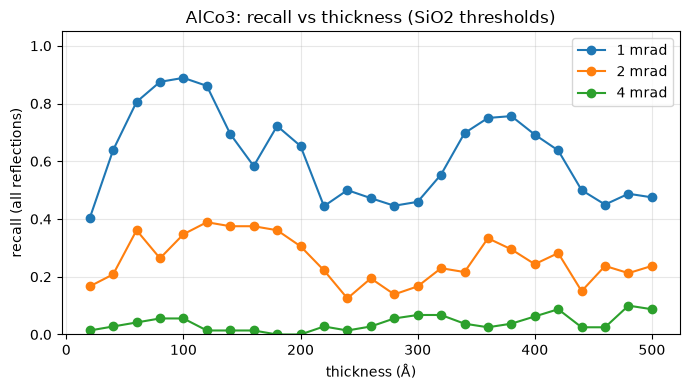

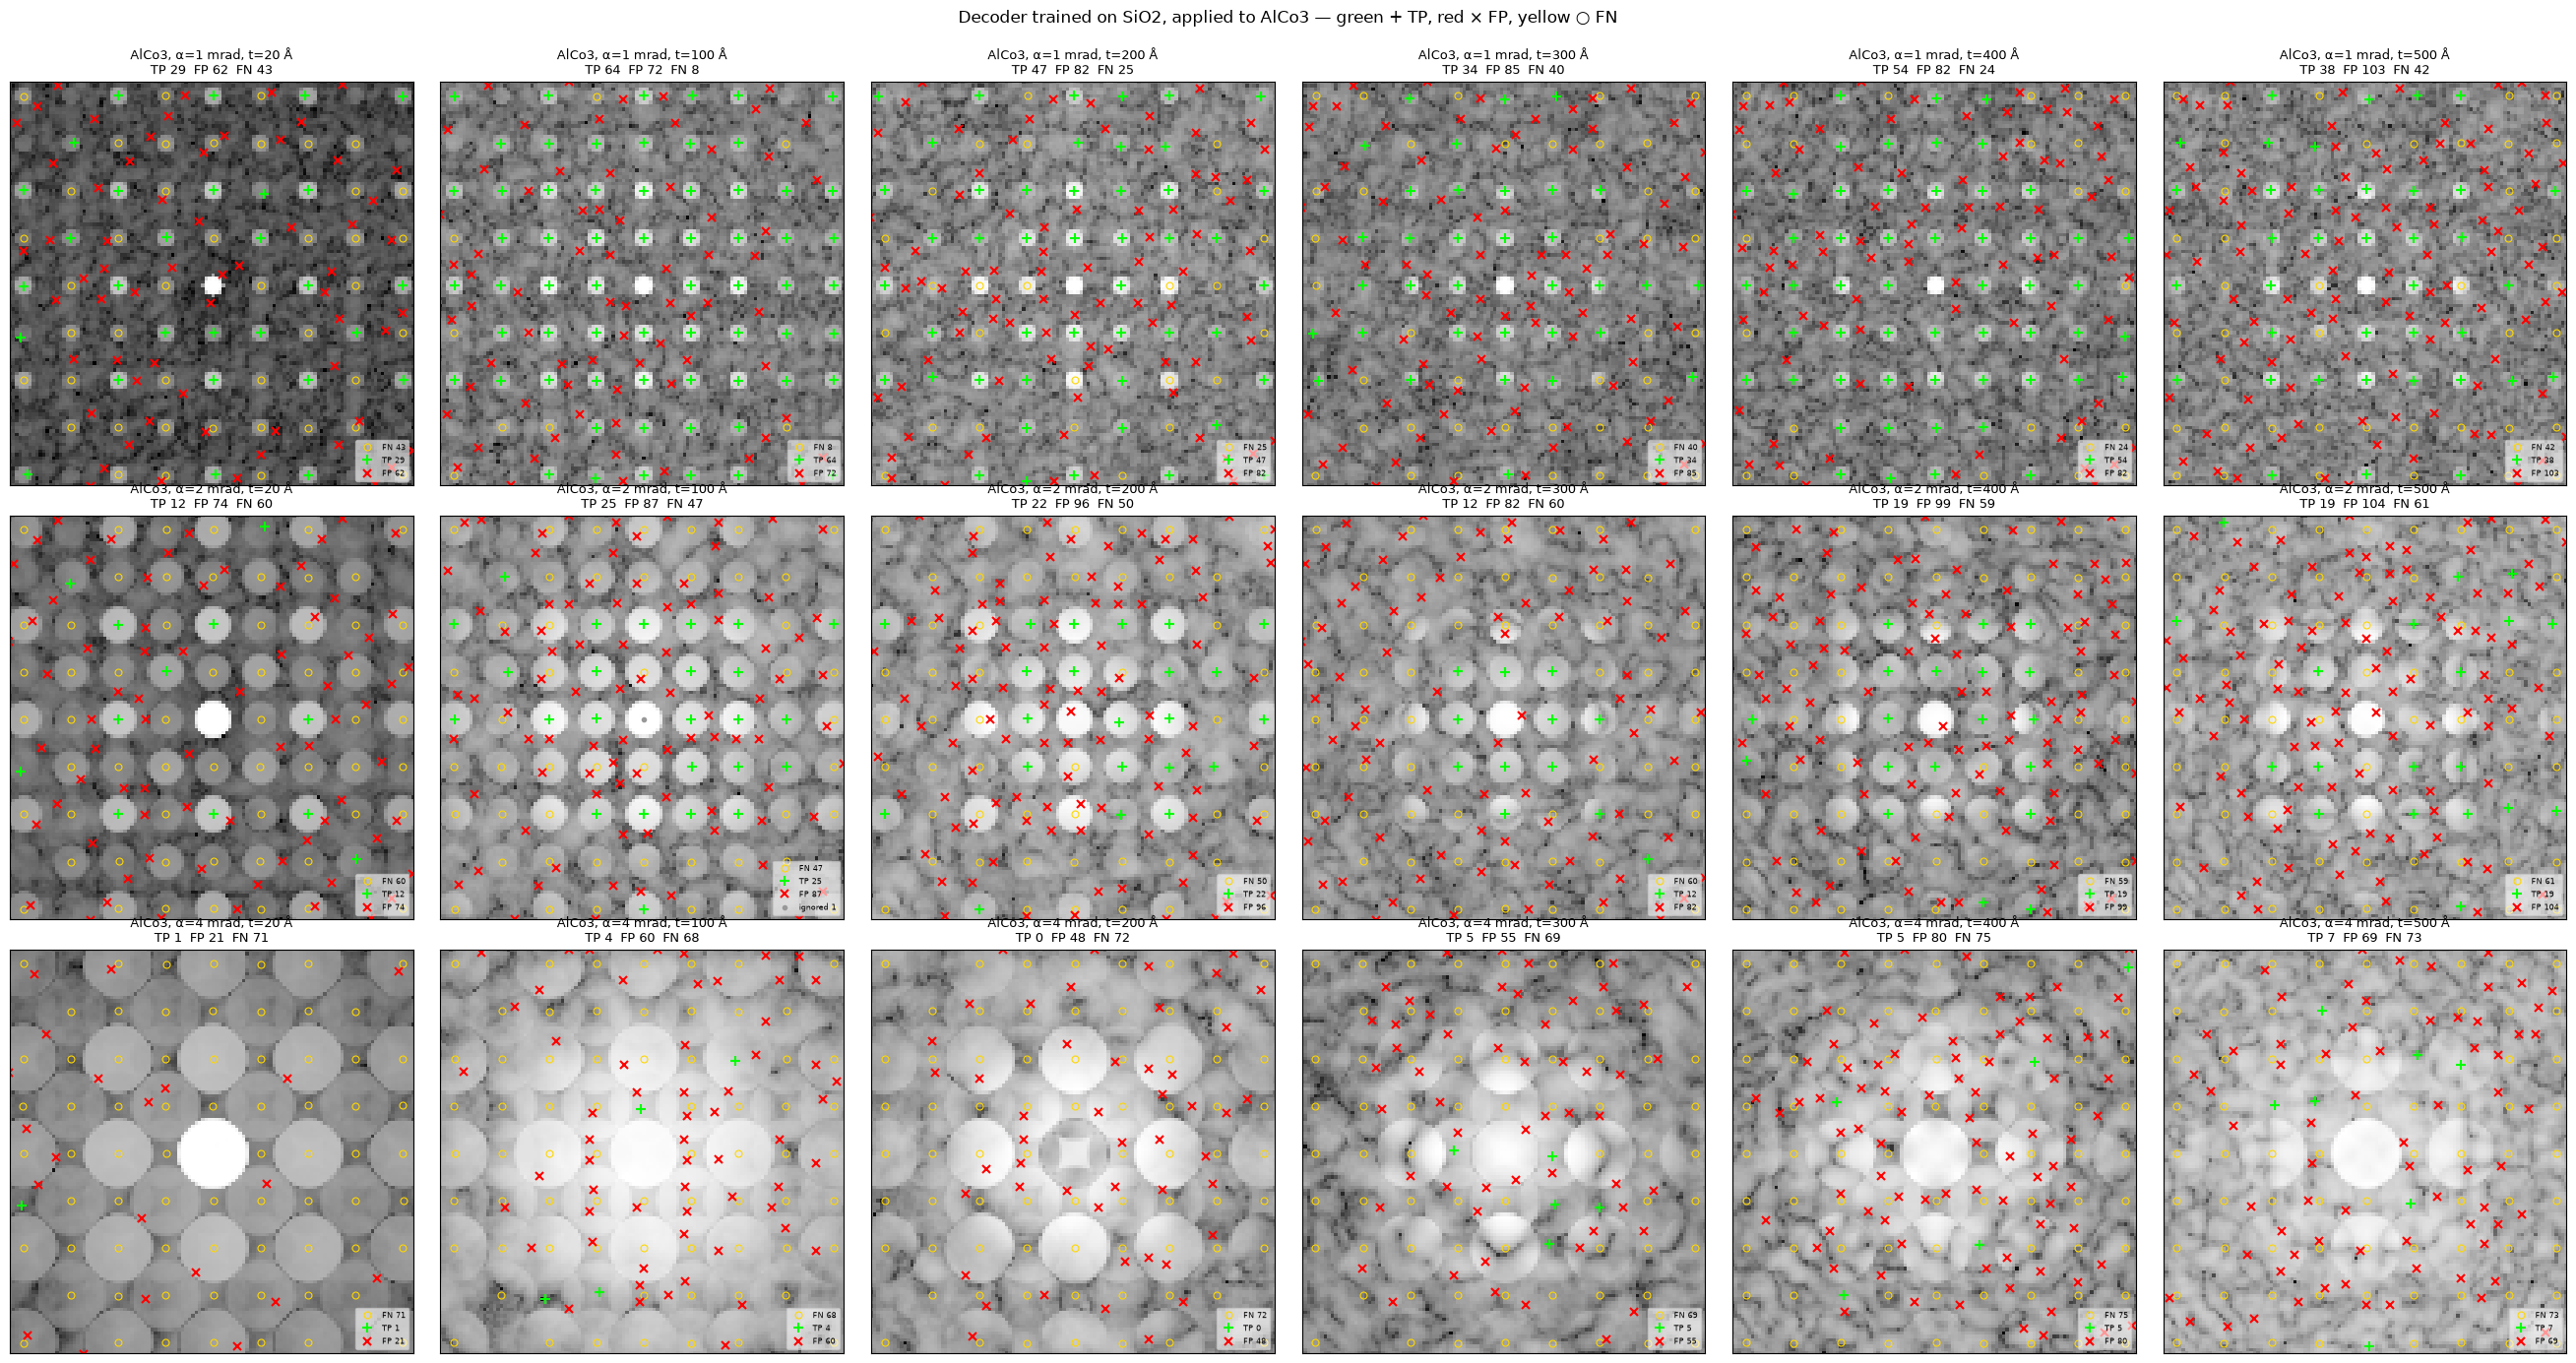

,mrad,thickness,row_px,col_px,qx,qy,score
0,1,20,128.050,183.941,1.007e-03,1.119e+00,1.000
1,1,20,156.019,99.989,5.604e-01,-5.602e-01,1.000
2,1,20,128.196,72.042,3.927e-03,-1.119e+00,0.999
3,1,20,128.024,99.973,4.892e-04,-5.605e-01,0.997
4,1,20,99.950,156.043,-5.610e-01,5.609e-01,0.996
5,1,20,155.925,128.046,5.585e-01,9.297e-04,0.992
6,1,20,114.046,142.042,-2.791e-01,2.808e-01,0.992
7,1,20,113.846,114.095,-2.831e-01,-2.781e-01,0.991
8,1,20,100.056,100.034,-5.589e-01,-5.593e-01,0.990
9,1,20,155.929,156.080,5.586e-01,5.616e-01,0.985


In [ ]:
# ── Apply the trained decoder (A) to a new crystal from selected_folders ────
# Run cells 14–22 first: needs backbone/encode, ground_truth/match, norm_log, dec, decoder_detect, tp_fp_fn, thr.
NEW_ROOT = Path("/mnt/data/DINOV3/dinov3/dummy_data/selected_folders")
NEW_UUID = "0c6670dd-6029-42cf-ab7b-cdbc8713c22d"      # AlCo3, Pm-3m (cubic). Any folder name in NEW_ROOT works.
T_SHOW   = [0, 4, 9, 14, 19, 24]                        # thickness indices shown in the overlay figure

new_dir  = NEW_ROOT / NEW_UUID
new_meta = pd.read_pickle(new_dir / "simulation_dataframe.pkl"); new_meta.index = new_meta.index.astype(str)
new_sims = [load_sim(p) for p in sorted(new_dir.glob("*_training.h5"))]
for s in new_sims:
    s["meta"] = new_meta.loc[s["uuid"]]
new_sims.sort(key=lambda s: s["meta"]["probeSemiangle"])
m0 = new_sims[0]["meta"]
print(f"{m0['pretty_formula']} ({m0['space_group_symbol']}, {m0['space_group_system']}, {m0['mat_id']}): "
      f"{len(new_sims)} files, α = {[int(s['meta']['probeSemiangle']) for s in new_sims]} mrad")

# Same inputs as in training: DINOv3 tokens + log-scaled diffraction crop + probe crop.
# Thresholds are the per-angle 5 FP/img thresholds `thr` tuned on the SiO2 held-out set (not re-tuned here).
dec.eval()
new_rows, new_spots = [], []
for fi, s in enumerate(new_sims):
    mr = s["meta"]["probeSemiangle"]
    _, feats = encode([s["dataMeas"][..., t] for t in T_EVAL], mode="log")
    x_probe = crop(s["dataProbe"]).astype(np.float32)
    for t, feat in zip(T_EVAL, feats):
        d = dict(feat=feat, x_img=np.stack([norm_log(crop(s["dataMeas"][..., t])), x_probe]).astype(np.float32))
        det, sc, p = decoder_detect(d)
        keep = in_region(det); det, sc = det[keep], sc[keep]
        gt = ground_truth(s, t)
        new_rows.append(dict(file=fi, mrad=mr, t_idx=t, thickness=s["thicknesses"][t], det=det, scores=sc, heat=p,
                             **match(det, gt), n_vis=int(gt["visible"].sum()), n_all=len(gt["centers"])))
        for (r, c), v in zip(det[sc >= thr[mr]], sc[sc >= thr[mr]]):      # predicted spot list at the fixed threshold
            new_spots.append(dict(mrad=mr, thickness=s["thicknesses"][t], row_px=r, col_px=c,
                                  qx=np.interp(r, np.arange(IMG), s["qx"]), qy=np.interp(c, np.arange(IMG), s["qy"]),
                                  score=v))
    del feats
new_spots = pd.DataFrame(new_spots)
print(f"{len(new_spots)} predicted spots over {len(new_rows)} patterns")

# Counts at the fixed SiO2 thresholds (all-reflections protocol), per angle and thickness
new_counts = []
for r in new_rows:
    s = new_sims[r["file"]]; gt = ground_truth(s, r["t_idx"])
    tp, fp, ig, fn = tp_fp_fn(r["det"][r["scores"] >= thr[r["mrad"]]], gt["centers"], gt["direct"][None])
    new_counts.append(dict(mrad=r["mrad"], thickness=r["thickness"], GT=len(gt["centers"]),
                           TP=len(tp), FP=len(fp), FN=len(fn)))
new_counts = pd.DataFrame(new_counts)
tot = new_counts.groupby("mrad")[["GT", "TP", "FP", "FN"]].sum()
tot["recall"] = tot.TP / tot.GT.clip(lower=1); tot["precision"] = tot.TP / (tot.TP + tot.FP).clip(lower=1)
tot["FP/img"] = tot.FP / new_counts.groupby("mrad").size()
print("At the fixed SiO2 thresholds (all reflections, all 25 thicknesses):"); display(tot)
print("Threshold-free view: recall at 1 / 5 FP per image, thresholds picked on this crystal (optimistic):")
display(summarise(new_rows).T)

# Recall vs thickness at the fixed thresholds
fig, ax = plt.subplots(figsize=(7, 4))
for mr, g in new_counts.groupby("mrad"):
    ax.plot(g.thickness, g.TP / g.GT.clip(lower=1), marker="o", label=f"{mr} mrad")
ax.set_xlabel("thickness (Å)"); ax.set_ylabel("recall (all reflections)"); ax.set_ylim(0, 1.05); ax.grid(alpha=0.3)
ax.set_title(f"{m0['pretty_formula']}: recall vs thickness (SiO2 thresholds)"); ax.legend()
plt.tight_layout(); plt.show()

# TP / FP / FN overlay: one row per angle, one column per thickness in T_SHOW
fig, axes = plt.subplots(len(new_sims), len(T_SHOW), figsize=(4.4 * len(T_SHOW), 4.6 * len(new_sims)), squeeze=False)
for row, (fi, s) in zip(axes, enumerate(new_sims)):
    mr = s["meta"]["probeSemiangle"]
    for ax, t in zip(row, T_SHOW):
        r = next(r for r in new_rows if r["file"] == fi and r["t_idx"] == t)
        gt = ground_truth(s, t)
        tp, fp, ig, fn = tp_fp_fn(r["det"][r["scores"] >= thr[mr]], gt["centers"], gt["direct"][None])
        ax.imshow(np.log10(crop(s["dataMeas"][..., t]) + 1e-8), extent=ext, cmap="gray")
        ax.plot(fn[:, 1], fn[:, 0], "o", mfc="none", mec="gold", ms=5, mew=0.8, label=f"FN {len(fn)}")
        ax.plot(tp[:, 1], tp[:, 0], "+", color="lime", ms=7, mew=1.5, label=f"TP {len(tp)}")
        ax.plot(fp[:, 1], fp[:, 0], "x", color="red", ms=6, mew=1.5, label=f"FP {len(fp)}")
        if len(ig): ax.plot(ig[:, 1], ig[:, 0], ".", color="0.6", ms=6, label=f"ignored {len(ig)}")
        ax.set_xlim(LO, HI); ax.set_ylim(HI, LO); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{label(s)}, t={s['thicknesses'][t]} Å\nTP {len(tp)}  FP {len(fp)}  FN {len(fn)}", fontsize=9)
        ax.legend(fontsize=6, loc="lower right", framealpha=0.6)
fig.suptitle(f"Decoder trained on SiO2, applied to {m0['pretty_formula']} — green + TP, red × FP, yellow ○ FN", y=1.0)
plt.tight_layout(); plt.show()

new_spots.head(10)    # predicted spot centres: detector px and q (1/Å)